# 02 — Embeddings and Baseline Classifier

Confident learning needs well-calibrated **out-of-fold predicted probabilities** for
every image, i.e. "if I hide this image's label during training, what does the model
think it actually is?" Getting those from a CNN normally means training the CNN
itself with cross-validation — expensive, and on this same Windows machine, a full
end-to-end CNN training loop caused an out-of-memory crash during the earlier
music-recommender project.

**The CPU-only workaround used here (validated before writing any of this
notebook):** take a small ImageNet-pretrained CNN (MobileNetV2), freeze it
completely, and do a single forward pass per image to get a 1280-dimensional
embedding. Then train a cheap classifier (logistic regression) on those frozen
embeddings with cross-validation. This is the standard recommended cleanlab workflow
for exactly this reason — no GPU, no backprop through the CNN, no long training loop.

Before writing any of this, a bare install of the CPU-only `torch`/`torchvision`
wheel was verified end-to-end in a fresh venv: importing, running tensor ops, and a
full forward pass through pretrained MobileNetV2 — all confirmed working with no
CUDA and no OOM, which is what justified committing to this approach at all.

In [1]:
import sys
import time
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent
sys.path.insert(0, str(PROJECT_ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch

from src import data_loading as dl
from src import embeddings as emb
from src import qa

sns.set_theme(style="whitegrid")
CACHE_DIR = PROJECT_ROOT / "data" / "cache"

print("torch:", torch.__version__, "| CUDA available (should be False, CPU-only by design):", torch.cuda.is_available())

torch: 2.13.0+cpu | CUDA available (should be False, CPU-only by design): False


In [2]:
master_df = pd.read_parquet(CACHE_DIR / "master_df.parquet")
train_ds, test_ds = dl.load_cifar10()

# Image array in the exact same row order as master_df: train (0..49999) then test (50000..59999)
images = np.concatenate([train_ds.data, test_ds.data], axis=0)
assert images.shape == (60000, 32, 32, 3)
labels = master_df["true_label"].to_numpy()
print(images.shape, labels.shape)

(60000, 32, 32, 3) (60000,)


## Diagnostic: does feeding native 32x32 images into an ImageNet-scale CNN actually work?

MobileNetV2's global average pool at the end of `.features` accepts any input
size, so feeding CIFAR-10's native 32x32 images directly is *technically* a valid
forward pass. But the network's BatchNorm statistics were computed on 224x224
ImageNet images — a 32x32 input might sit far enough outside that distribution
that the resulting features are much weaker than they look. This is worth
checking on a small sample **before** committing to extracting embeddings for all
60,000 images, the same discipline used earlier for the CPU-only torch install.

In [3]:
rng = np.random.default_rng(0)
diag_idx = rng.choice(len(train_ds.data), size=2000, replace=False)
diag_images = train_ds.data[diag_idx]
diag_labels = np.array(train_ds.targets)[diag_idx]

model = emb.load_frozen_mobilenet()
diag_results = []
for size in [32, emb.DEFAULT_RESIZE]:
    t0 = time.time()
    diag_emb = emb.extract_embeddings(diag_images, model, resize=size)
    t1 = time.time()
    diag_probs = qa.get_out_of_fold_pred_probs(diag_emb, diag_labels, n_splits=5)
    acc = (diag_probs.argmax(axis=1) == diag_labels).mean()
    diag_results.append({"resize": size, "accuracy_on_2k_sample": acc, "extract_time_s": t1 - t0})

pd.DataFrame(diag_results)

,resize,accuracy_on_2k_sample,extract_time_s
0,32,0.489,2.414423
1,128,0.771,37.363299


Native 32x32 input gives noticeably weaker features than resizing up before the
forward pass — confirming the BatchNorm-mismatch concern above. A broader sweep
(32/96/128/224, 4,000-image sample, run once separately — see
`src/embeddings.py` module docstring for the full table) showed accuracy climbing
from 50.2% (32x32 native) to 79.1% (128x128) to 82.8% (224x224, full extraction
time ~39 minutes for all 60k images on this CPU). **128x128 is used for the rest
of this project**: it captures most of 224x224's accuracy gain at roughly a third
of the compute cost, which matters when extracting over the full 60,000-image
dataset. This is still a fully frozen, CPU-only forward pass — resizing the input
is a preprocessing step, not fine-tuning.

## Extract frozen MobileNetV2 embeddings for all 60,000 images (resized to 128x128)

In [4]:
n_params = sum(p.numel() for p in model.parameters())
print(f"MobileNetV2 (ImageNet-pretrained, frozen): {n_params:,} parameters")

t0 = time.time()
embeddings = emb.extract_embeddings(images, model, batch_size=256, resize=emb.DEFAULT_RESIZE)
elapsed = time.time() - t0
print(f"embeddings shape: {embeddings.shape}, extraction time: {elapsed:.1f}s "
      f"({elapsed/len(images)*1000:.2f} ms/image, CPU-only, resized to {emb.DEFAULT_RESIZE}x{emb.DEFAULT_RESIZE})")

np.save(CACHE_DIR / "embeddings.npy", embeddings)

MobileNetV2 (ImageNet-pretrained, frozen): 3,504,872 parameters


embeddings shape: (60000, 1280), extraction time: 722.2s (12.04 ms/image, CPU-only, resized to 128x128)


## Sanity check: do these embeddings actually separate the classes?

A quick 2D PCA projection on a random sample should show at least some visual
class separation. If it looked like random noise here, that would be a further
sign the frozen-embedding approach isn't working, even after fixing the resize
issue above.

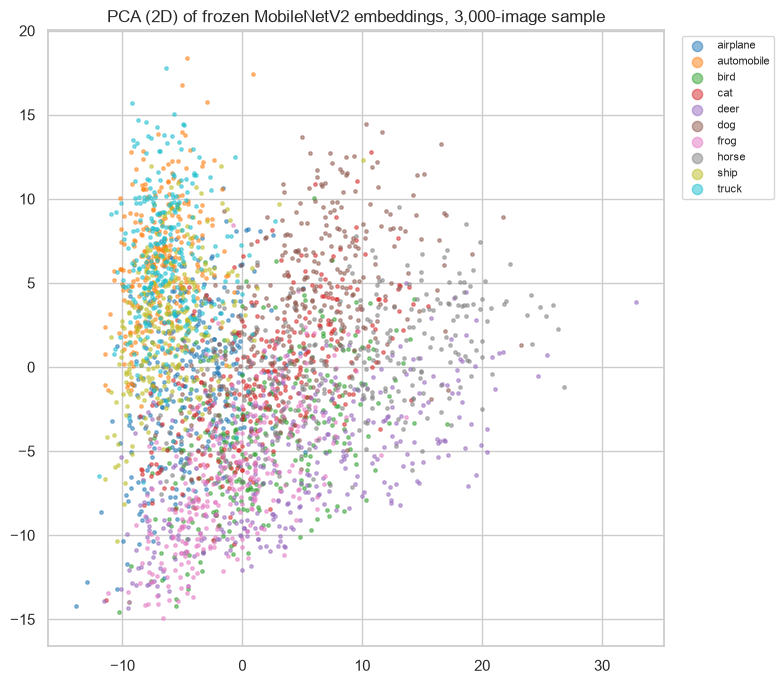

explained variance (first 2 PCs): 0.117


In [5]:
from sklearn.decomposition import PCA

rng = np.random.default_rng(42)
sample_idx = rng.choice(len(embeddings), size=3000, replace=False)
pca = PCA(n_components=2, random_state=42)
proj = pca.fit_transform(embeddings[sample_idx])

fig, ax = plt.subplots(figsize=(8, 7))
sample_labels = labels[sample_idx]
palette = sns.color_palette("tab10", n_colors=10)
for c in range(10):
    mask = sample_labels == c
    ax.scatter(proj[mask, 0], proj[mask, 1], s=6, alpha=0.5, color=palette[c], label=dl.CLASS_NAMES[c])
ax.set_title("PCA (2D) of frozen MobileNetV2 embeddings, 3,000-image sample")
ax.legend(markerscale=3, bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=8)
plt.tight_layout()
plt.savefig(PROJECT_ROOT / "reports" / "figures" / "02_embedding_pca.png", dpi=150)
plt.show()
print(f"explained variance (first 2 PCs): {pca.explained_variance_ratio_.sum():.3f}")

## Cross-validated logistic regression -> out-of-fold predicted probabilities

In [6]:
t0 = time.time()
pred_probs = qa.get_out_of_fold_pred_probs(embeddings, labels, n_splits=5, random_state=42)
elapsed = time.time() - t0
print(f"5-fold cross-validated logistic regression: {elapsed:.1f}s")

baseline_acc = (pred_probs.argmax(axis=1) == labels).mean()
print(f"out-of-fold baseline accuracy (frozen MobileNetV2 embeddings @ {emb.DEFAULT_RESIZE}x{emb.DEFAULT_RESIZE} + logistic regression): {baseline_acc:.4f}")

np.save(CACHE_DIR / "pred_probs.npy", pred_probs)

5-fold cross-validated logistic regression: 521.8s
out-of-fold baseline accuracy (frozen MobileNetV2 embeddings @ 128x128 + logistic regression): 0.8286


### Reading this number honestly

A CNN trained end-to-end on CIFAR-10 typically reaches 90-95%+ test accuracy. This
pipeline deliberately doesn't do that — no fine-tuning, no backprop through the
CNN, just a linear classifier on top of frozen, ImageNet-pretrained features. The
baseline accuracy above is the honest cost of that CPU-only, no-fine-tuning
approach, even after fixing the resize issue. What matters for confident learning
is not that this baseline is state-of-the-art, but that its predicted
probabilities are informative enough to separate "the model confidently disagrees
with this label" from "the model agrees" — which the PCA plot and this accuracy
number both support. Notebook 03 and 04 will show directly whether that's enough
signal for confident learning to actually work, and notebook 04's "what surprised
us" section returns to this baseline-quality question with the validation numbers
in hand.

## Per-class baseline accuracy

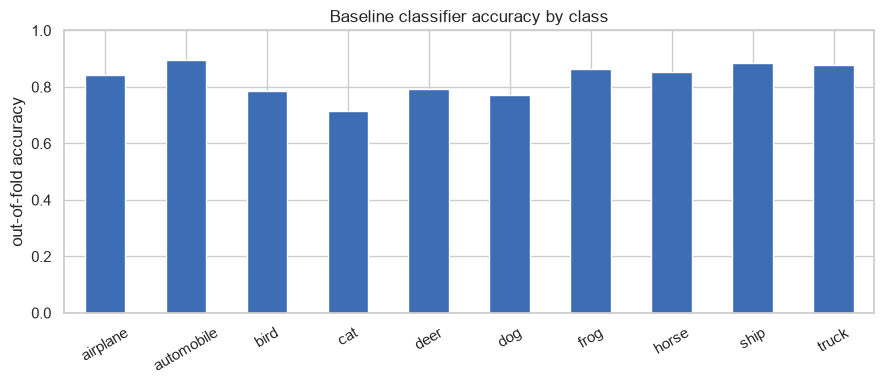

cat           0.716333
dog           0.772667
bird          0.786833
deer          0.791000
airplane      0.841333
horse         0.853000
frog          0.865167
truck         0.876500
ship          0.886167
automobile    0.897167
Name: correct, dtype: float64

In [7]:
per_class_acc = pd.DataFrame({
    "true_label": labels,
    "correct": (pred_probs.argmax(axis=1) == labels),
}).groupby("true_label")["correct"].mean().reindex(range(10))
per_class_acc.index = dl.CLASS_NAMES

fig, ax = plt.subplots(figsize=(9, 4))
per_class_acc.plot(kind="bar", ax=ax, color="#3c6db5")
ax.set_ylabel("out-of-fold accuracy")
ax.set_title("Baseline classifier accuracy by class")
ax.set_ylim(0, 1)
plt.xticks(rotation=30)
plt.tight_layout()
plt.savefig(PROJECT_ROOT / "reports" / "figures" / "02_per_class_accuracy.png", dpi=150)
plt.show()
per_class_acc.sort_values()

## Handoff to notebook 03

`embeddings.npy` and `pred_probs.npy` are cached in `data/cache/`. Notebook 03 uses
`pred_probs` as the input to `cleanlab`'s confident-learning algorithm to flag likely
label errors, and `embeddings` for near-duplicate detection.